# Task 1 — LoRA fine-tuning: plain English → meeting/reminder JSON

**Model:** `Qwen/Qwen2.5-0.5B-Instruct` · **Method:** LoRA on frozen fp16 weights · **Hardware:** Kaggle T4 (16 GB, fp16 only)

What this notebook does, top to bottom:

1. Install pinned libraries
2. Load `train.jsonl` / `test.jsonl` (made by `generate_data.py`)
3. Load the base model and define **one** prompt format used for both models
4. Evaluate the **base** model on the test set (greedy decoding)
5. Train LoRA adapters (loss only on the answer tokens)
6. Evaluate the **fine-tuned** model on the same test set
7. Save predictions, metrics, failures, loss log and peak GPU memory to `results/`, print a comparison table

**Kaggle settings:** Accelerator → *GPU T4 x2* (only one GPU is used) · Internet → *On* · Add your dataset containing `train.jsonl` and `test.jsonl`.

## 1. Install pinned libraries

In [1]:
# Pinned versions so the run is reproducible. torch is not reinstalled: we use Kaggle's CUDA build.
# bitsandbytes is only needed for 4-bit QLoRA. It is installed as required, but this run
# trains LoRA on fp16 weights and does not use it.
!pip install -q transformers==4.57.1 peft==0.17.1 accelerate==1.10.1 datasets==4.1.1 bitsandbytes==0.48.1

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # Kaggle "T4 x2" has two GPUs; use one so batch size 8 really means 8

import glob
import json
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from datasets import Dataset
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments, set_seed

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
SEED = 42
MAX_NEW_TOKENS = 128
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

set_seed(SEED)
assert torch.cuda.is_available(), "No GPU found: turn on the T4 GPU in the notebook settings."
print("torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0))

I0000 00:00:1795236184.859245     202 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


torch 2.11.0+cu130 | GPU: Tesla T4


## 2. Load the data

In [3]:
def find_data_dir():
    """Use ./data if it exists (local run); otherwise search the Kaggle input folder."""
    if Path("data/train.jsonl").exists():
        return Path("data")
    matches = glob.glob("/kaggle/input/**/train.jsonl", recursive=True)
    if not matches:
        raise FileNotFoundError("train.jsonl not found. Add the dataset with train.jsonl and test.jsonl to the notebook.")
    return Path(matches[0]).parent


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]


def save_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as f:
        for row in rows:
            f.write(json.dumps(row, ensure_ascii=False) + "\n")


DATA_DIR = find_data_dir()
train_rows = read_jsonl(DATA_DIR / "train.jsonl")
test_rows = read_jsonl(DATA_DIR / "test.jsonl")
print(f"Data from {DATA_DIR}: {len(train_rows)} train, {len(test_rows)} test "
      f"({sum(r['unseen_template'] for r in test_rows)} test examples use unseen templates)")
print(train_rows[0])

Data from /kaggle/input/datasets/konabharath/tndrr-task1-data: 400 train, 60 test (30 test examples use unseen templates)
{'id': 'train-000', 'text': 'Cancel the project sync on 8 December.', 'output': {'action': 'cancel_meeting', 'title': 'project sync', 'date': '2026-12-08', 'time': None, 'duration_minutes': None, 'attendees': []}, 'template': 'Cancel the {title} {date}.', 'unseen_template': False}


## 3. Load the base model and define the prompt

The **same** system prompt and Qwen chat template are used for the base model, for training, and for the fine-tuned model.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.padding_side = "left"  # batched generation: pad on the left so every prompt ends where its answer starts

# fp16 weights (a T4 has no bf16 support): ~0.5B params x 2 bytes = ~1 GB of GPU memory
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16).to("cuda")
print(f"Model parameters: {model.num_parameters() / 1e6:.0f}M | eos token: {tokenizer.eos_token!r} | pad token: {tokenizer.pad_token!r}")

Model parameters: 494M | eos token: '<|im_end|>' | pad token: '<|endoftext|>'


In [5]:
SYSTEM_PROMPT = """You convert a meeting or reminder request into JSON.
Today is Friday, 2026-11-20.
Reply with only one JSON object with exactly these keys:
{"action": "schedule_meeting" | "set_reminder" | "cancel_meeting", "title": string, "date": "YYYY-MM-DD" or null, "time": "HH:MM" (24-hour) or null, "duration_minutes": integer or null, "attendees": list of names}
Copy the title as it is written in the request. Use null for a date, time or duration that is not mentioned, and [] if no attendees are mentioned."""

FIELDS = ["action", "title", "date", "time", "duration_minutes", "attendees"]


def build_prompt(text):
    """System prompt + user request in Qwen's chat format, ending with the assistant header,
    so the next tokens the model writes are its answer."""
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": text},
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)


def to_target(output):
    """The exact answer string the model should learn to produce."""
    return json.dumps(output, ensure_ascii=False)


print(build_prompt(train_rows[0]["text"]) + to_target(train_rows[0]["output"]))

<|im_start|>system
You convert a meeting or reminder request into JSON.
Today is Friday, 2026-11-20.
Reply with only one JSON object with exactly these keys:
{"action": "schedule_meeting" | "set_reminder" | "cancel_meeting", "title": string, "date": "YYYY-MM-DD" or null, "time": "HH:MM" (24-hour) or null, "duration_minutes": integer or null, "attendees": list of names}
Copy the title as it is written in the request. Use null for a date, time or duration that is not mentioned, and [] if no attendees are mentioned.<|im_end|>
<|im_start|>user
Cancel the project sync on 8 December.<|im_end|>
<|im_start|>assistant
{"action": "cancel_meeting", "title": "project sync", "date": "2026-12-08", "time": null, "duration_minutes": null, "attendees": []}


## 4. Evaluation helpers

* **Valid JSON:** the text from the first `{` to the last `}` parses as a JSON object (so a ```` ```json ```` fence is tolerated, for both models).
* **Exact match:** the parsed object equals the label exactly (same 6 keys, same values).
* **Per-field accuracy:** for each key, the share of test examples where that key is present and correct. Invalid JSON counts as wrong for every field.

In [6]:
def extract_json(text):
    """Parse the model output into a dict, or return None if it is not valid JSON."""
    start, end = text.find("{"), text.rfind("}")
    if start == -1 or end < start:
        return None
    try:
        parsed = json.loads(text[start:end + 1])
    except json.JSONDecodeError:
        return None
    return parsed if isinstance(parsed, dict) else None


@torch.no_grad()
def generate_answers(model, texts, batch_size=16):
    """Greedy decoding for a list of requests. Returns the generated strings."""
    model.eval()
    answers = []
    for i in range(0, len(texts), batch_size):
        prompts = [build_prompt(t) for t in texts[i:i + batch_size]]
        inputs = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=False,                           # greedy: always take the most likely next token
            temperature=None, top_p=None, top_k=None,  # clear Qwen's default sampling settings
            repetition_penalty=1.0,                    # Qwen's default is 1.05; 1.0 = plain greedy
            pad_token_id=tokenizer.pad_token_id,
        )
        new_tokens = generated[:, inputs["input_ids"].shape[1]:]  # keep only the answer, drop the prompt
        answers += tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
    return answers


def evaluate(model, rows, name):
    """Run the model on the rows, score each prediction, save results/<name>_predictions.jsonl."""
    raw_outputs = generate_answers(model, [r["text"] for r in rows])
    preds = []
    for row, raw in zip(rows, raw_outputs):
        gold, parsed = row["output"], extract_json(raw)
        preds.append({
            "id": row["id"],
            "text": row["text"],
            "unseen_template": row["unseen_template"],
            "gold": gold,
            "raw_output": raw,
            "parsed": parsed,
            "valid_json": parsed is not None,
            "exact_match": parsed == gold,
            "field_correct": {f: parsed is not None and f in parsed and parsed[f] == gold[f] for f in FIELDS},
        })
    save_jsonl(preds, RESULTS_DIR / f"{name}_predictions.jsonl")
    return preds


def rate(preds, key):
    return round(sum(p[key] for p in preds) / len(preds), 4)


def compute_metrics(preds):
    seen = [p for p in preds if not p["unseen_template"]]
    unseen = [p for p in preds if p["unseen_template"]]
    return {
        "n_examples": len(preds),
        "valid_json_rate": rate(preds, "valid_json"),
        "exact_match": rate(preds, "exact_match"),
        "exact_match_seen_templates": rate(seen, "exact_match"),
        "exact_match_unseen_templates": rate(unseen, "exact_match"),
        "field_accuracy": {f: round(sum(p["field_correct"][f] for p in preds) / len(preds), 4) for f in FIELDS},
    }

## 5. Evaluate the base model

In [7]:
start = time.time()
base_preds = evaluate(model, test_rows, "base")
base_metrics = compute_metrics(base_preds)
print(f"Base model evaluated in {time.time() - start:.0f}s")
print(json.dumps(base_metrics, indent=2))

for p in base_preds[:3]:
    print("\nINPUT :", p["text"])
    print("OUTPUT:", p["raw_output"])

Base model evaluated in 10s
{
  "n_examples": 60,
  "valid_json_rate": 1.0,
  "exact_match": 0.0,
  "exact_match_seen_templates": 0.0,
  "exact_match_unseen_templates": 0.0,
  "field_accuracy": {
    "action": 0.85,
    "title": 0.05,
    "date": 0.3833,
    "time": 0.7333,
    "duration_minutes": 0.9,
    "attendees": 0.4833
  }
}

INPUT : Something came up, please scrap the budget review today at 12:30PM.
OUTPUT: {"action": "cancel_meeting", "title": "Budget Review", "date": "2026-11-20", "time": "12:30", "duration_minutes": null, "attendees": null}

INPUT : Cancel my budget review with Zara in 13 days at noon.
OUTPUT: {"action": "cancel_meeting", "title": "budget review", "date": "2026-11-16", "time": "13:00", "duration_minutes": null, "attendees": null}

INPUT : Delete the code review at 10:30am on Thursday from my calendar.
OUTPUT: {"action": "delete_calendar_entry", "title": "code review", "date": "2026-11-19", "time": "10:30", "duration_minutes": null, "attendees": null}


## 6. Prepare the training data

Each training sequence is `prompt + answer + <|im_end|>`. The labels are `-100` for every prompt token, and `-100` means "ignore" in PyTorch's cross-entropy, so the loss is computed **only on the answer tokens**. The model learns to write the answer, not to repeat the prompt.

In [8]:
def tokenize_example(row):
    prompt_ids = tokenizer(build_prompt(row["text"]), add_special_tokens=False)["input_ids"]
    # eos (<|im_end|>) ends the answer, so the model also learns when to stop
    answer_ids = tokenizer(to_target(row["output"]) + tokenizer.eos_token, add_special_tokens=False)["input_ids"]
    return {
        "input_ids": prompt_ids + answer_ids,
        "attention_mask": [1] * (len(prompt_ids) + len(answer_ids)),
        "labels": [-100] * len(prompt_ids) + answer_ids,
    }


train_ds = Dataset.from_list([tokenize_example(r) for r in train_rows])
lengths = [len(ids) for ids in train_ds["input_ids"]]
print(f"{len(train_ds)} training sequences, {min(lengths)}-{max(lengths)} tokens long")

# Sanity check: these are the only tokens the loss is computed on
example = train_ds[0]
print("Loss is computed on:", repr(tokenizer.decode([t for t in example["labels"] if t != -100])))


def collate(batch):
    """Right-pad a batch to its longest sequence. Padding gets attention_mask 0
    (ignored by attention) and label -100 (ignored by the loss)."""
    max_len = max(len(x["input_ids"]) for x in batch)

    def pad(values, pad_value):
        return values + [pad_value] * (max_len - len(values))

    return {
        "input_ids": torch.tensor([pad(x["input_ids"], tokenizer.pad_token_id) for x in batch]),
        "attention_mask": torch.tensor([pad(x["attention_mask"], 0) for x in batch]),
        "labels": torch.tensor([pad(x["labels"], -100) for x in batch]),
    }

400 training sequences, 199-254 tokens long
Loss is computed on: '{"action": "cancel_meeting", "title": "project sync", "date": "2026-12-08", "time": null, "duration_minutes": null, "attendees": []}<|im_end|>'


## 7. Add LoRA adapters and train

LoRA freezes every original weight `W` and learns a small update `ΔW = B·A` (rank `r`) for the attention projections. Only `A` and `B` are trained.

In [9]:
lora_config = LoraConfig(
    r=16,                 # rank of the update matrices A (r x d_in) and B (d_out x r)
    lora_alpha=32,        # the update is scaled by alpha / r = 2
    lora_dropout=0.05,    # dropout on the LoRA input, light regularisation for a small dataset
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],  # attention projections in every layer
    bias="none",
    task_type="CAUSAL_LM",
)
model = get_peft_model(model, lora_config)

# The frozen base weights stay fp16 to save memory. The small trainable LoRA weights are kept
# in fp32: fp16 mixed-precision training (GradScaler) cannot update fp16 weights, and fp32
# weights make the small updates numerically stable. (Recent PEFT versions already do this by
# default via autocast_adapter_dtype=True; the loop makes it explicit and version-independent.)
for param in model.parameters():
    if param.requires_grad:
        param.data = param.data.float()

model.print_trainable_parameters()

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


In [10]:
args = TrainingArguments(
    output_dir="outputs",
    num_train_epochs=3,
    learning_rate=2e-4,
    per_device_train_batch_size=8,   # 8 short sequences fit easily on a T4 for a 0.5B model.
    gradient_accumulation_steps=1,   # If you hit out-of-memory: batch size 4 and accumulation 2 (still 8 per update).
    lr_scheduler_type="linear",
    warmup_steps=10,
    fp16=True,                       # mixed precision: forward/backward in fp16, loss scaling against underflow
    logging_steps=5,
    save_strategy="no",              # no checkpoints needed; we save the adapter at the end
    report_to="none",                # no wandb / tensorboard
    remove_unused_columns=False,     # keep our labels column as is
    seed=SEED,
)

trainer = Trainer(model=model, args=args, train_dataset=train_ds, data_collator=collate)

torch.cuda.reset_peak_memory_stats()
start = time.time()
train_result = trainer.train()
train_seconds = time.time() - start

peak_allocated_gb = torch.cuda.max_memory_allocated() / 1024**3  # memory actually used by tensors
peak_reserved_gb = torch.cuda.max_memory_reserved() / 1024**3    # memory held by PyTorch's allocator (close to nvidia-smi)
print(f"Training took {train_seconds:.0f}s | peak GPU memory: {peak_allocated_gb:.2f} GB allocated, {peak_reserved_gb:.2f} GB reserved")

Step,Training Loss
5,0.152100
10,0.070200
15,0.043400
20,0.038900
25,0.024800
30,0.022000
35,0.014500
40,0.011500
45,0.017100
50,0.009000


Training took 59s | peak GPU memory: 6.96 GB allocated, 14.04 GB reserved


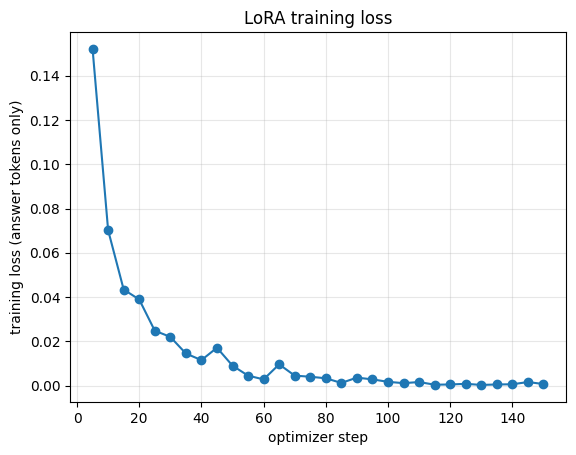

In [11]:
# Training loss log + plot
loss_log = [
    {"step": h["step"], "epoch": round(h["epoch"], 3), "loss": h["loss"], "learning_rate": h["learning_rate"]}
    for h in trainer.state.log_history if "loss" in h
]
with open(RESULTS_DIR / "train_loss_log.json", "w") as f:
    json.dump(loss_log, f, indent=2)

plt.plot([h["step"] for h in loss_log], [h["loss"] for h in loss_log], marker="o")
plt.xlabel("optimizer step")
plt.ylabel("training loss (answer tokens only)")
plt.title("LoRA training loss")
plt.grid(alpha=0.3)
plt.savefig(RESULTS_DIR / "train_loss.png", dpi=120, bbox_inches="tight")
plt.show()

model.save_pretrained("lora_adapter")  # only the small A/B matrices are saved

## 8. Evaluate the fine-tuned model (same prompt, same decoding)

In [12]:
start = time.time()
ft_preds = evaluate(model, test_rows, "finetuned")
ft_metrics = compute_metrics(ft_preds)
print(f"Fine-tuned model evaluated in {time.time() - start:.0f}s")
print(json.dumps(ft_metrics, indent=2))

Fine-tuned model evaluated in 15s
{
  "n_examples": 60,
  "valid_json_rate": 1.0,
  "exact_match": 0.8667,
  "exact_match_seen_templates": 0.9667,
  "exact_match_unseen_templates": 0.7667,
  "field_accuracy": {
    "action": 0.95,
    "title": 0.9667,
    "date": 0.95,
    "time": 1.0,
    "duration_minutes": 0.9833,
    "attendees": 0.9833
  }
}


## 9. Save failures and metrics, print the comparison

In [13]:
failures = [
    {
        "id": p["id"],
        "text": p["text"],
        "unseen_template": p["unseen_template"],
        "gold": p["gold"],
        "prediction": p["parsed"],
        "raw_output": p["raw_output"],
        "wrong_fields": [f for f in FIELDS if not p["field_correct"][f]],
    }
    for p in ft_preds if not p["exact_match"]
]
save_jsonl(failures, RESULTS_DIR / "failures.jsonl")
print(f"{len(failures)} test examples are still wrong after fine-tuning -> results/failures.jsonl")

metrics = {
    "model": MODEL_NAME,
    "base": base_metrics,
    "finetuned": ft_metrics,
    "training": {
        "train_examples": len(train_rows),
        "epochs": args.num_train_epochs,
        "learning_rate": args.learning_rate,
        "batch_size": args.per_device_train_batch_size * args.gradient_accumulation_steps,
        "optimizer_steps": trainer.state.global_step,
        "lora": {
            "r": lora_config.r,
            "alpha": lora_config.lora_alpha,
            "dropout": lora_config.lora_dropout,
            "target_modules": sorted(lora_config.target_modules),
        },
        "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "total_params": sum(p.numel() for p in model.parameters()),
        "average_train_loss": round(train_result.training_loss, 4),
        "last_logged_loss": loss_log[-1]["loss"],
        "train_time_seconds": round(train_seconds, 1),
        "peak_gpu_memory_allocated_gb": round(peak_allocated_gb, 2),
        "peak_gpu_memory_reserved_gb": round(peak_reserved_gb, 2),
        "gpu": torch.cuda.get_device_name(0),
    },
}
with open(RESULTS_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)


def table_rows(m):
    rows = {
        "Valid JSON rate": m["valid_json_rate"],
        "Exact match (all 60)": m["exact_match"],
        "Exact match (seen templates)": m["exact_match_seen_templates"],
        "Exact match (unseen templates)": m["exact_match_unseen_templates"],
    }
    for field, acc in m["field_accuracy"].items():
        rows[f"Field accuracy: {field}"] = acc
    return rows


base_rows, ft_rows = table_rows(base_metrics), table_rows(ft_metrics)
lines = ["| Metric | Base | Fine-tuned |", "|---|---|---|"]
for name in base_rows:
    lines.append(f"| {name} | {base_rows[name]:.1%} | {ft_rows[name]:.1%} |")
table = "\n".join(lines)
summary = (
    f"\n\nPeak GPU memory during training: {peak_allocated_gb:.2f} GB allocated / {peak_reserved_gb:.2f} GB reserved"
    f"\nTraining time: {train_seconds:.0f}s for {trainer.state.global_step} optimizer steps"
)
(RESULTS_DIR / "comparison.md").write_text(table + summary + "\n")
print(table + summary)

8 test examples are still wrong after fine-tuning -> results/failures.jsonl
| Metric | Base | Fine-tuned |
|---|---|---|
| Valid JSON rate | 100.0% | 100.0% |
| Exact match (all 60) | 0.0% | 86.7% |
| Exact match (seen templates) | 0.0% | 96.7% |
| Exact match (unseen templates) | 0.0% | 76.7% |
| Field accuracy: action | 85.0% | 95.0% |
| Field accuracy: title | 5.0% | 96.7% |
| Field accuracy: date | 38.3% | 95.0% |
| Field accuracy: time | 73.3% | 100.0% |
| Field accuracy: duration_minutes | 90.0% | 98.3% |
| Field accuracy: attendees | 48.3% | 98.3% |

Peak GPU memory during training: 6.96 GB allocated / 14.04 GB reserved
Training time: 59s for 150 optimizer steps


In [14]:
# One zip with everything in results/ (download it from the Output panel)
shutil.make_archive("results", "zip", RESULTS_DIR)
print(sorted(p.name for p in RESULTS_DIR.iterdir()))

['base_predictions.jsonl', 'comparison.md', 'failures.jsonl', 'finetuned_predictions.jsonl', 'metrics.json', 'train_loss.png', 'train_loss_log.json']


In [15]:
from IPython.display import FileLink
FileLink("results.zip")

/kaggle/working/results.zip